# ResNet：逐张画图

先运行下面三个准备单元格，然后独立运行想修改的那张图。

- **图1—4**：测试错误率、测试交叉熵、含噪训练错误率、含噪训练交叉熵。
- **图5—7**：9列、7列、完整12列预测对照；每格显示预测角色和置信度。
- 每张图的标题、画布大小、字号、颜色、展示宽度都写在对应单元格里。
- 图片对照默认沿用已选的 seed=44 和6张测试图片；修改 `SELECTED_SEED`、`SAMPLE_IDS` 可自行更换。
- 导出文件保存在 **figures_notebook/**。设 `SAVE_FIGURES=False` 可只在Notebook里预览。

数据：224×224输入，训练293张，其中29张错标（约10%）；验证62张，测试62张。图片对照属于按结果筛选的介绍示例。

## 准备1：导入和路径

In [17]:
from pathlib import Path
import os
import tempfile

# 通常打开Notebook后，工作目录就是本文件所在目录。
# 若找不到 results.csv，请将 DATA_DIR 改成你的 resnet224 目录。
DATA_DIR = Path(".").resolve()
OUTPUT_DIR = DATA_DIR / "figures_notebook"
OUTPUT_DIR.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "resnet-notebook-matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle, Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import display

print("读取数据：", DATA_DIR)
print("保存图片：", OUTPUT_DIR)


读取数据： /Users/chan/Desktop/大学教材/多元统计分析/多元小组作业/intro-classification/experiment/resnet224
保存图片： /Users/chan/Desktop/大学教材/多元统计分析/多元小组作业/intro-classification/experiment/resnet224/figures_notebook


## 准备2：字体、保存选项和展示图片

In [18]:
import seaborn as sns
import pubstyle as pb

# # 中文宋体；英文及数字Times New Roman。字体随实验目录保存。
# font_manager.fontManager.addfont(DATA_DIR / "fonts/simsun.ttc")
# font_manager.fontManager.addfont(DATA_DIR / "fonts/Times New Roman.ttf")
# plt.rcParams.update({
#     "font.family": ["Times New Roman", "SimSun"],
#     "font.size": 12,
#     "axes.unicode_minus": False,
#     "pdf.fonttype": 42,
#     "svg.fonttype": "path",
# })
pb.use()


SAVE_FIGURES = True
SAVE_FORMATS = ["png", "pdf", "svg"]
DPI = 180

ROLE_NAMES = {"lulu": "噜噜", "nailong": "奶龙", "naiwa": "奶蛙", "niulai": "牛来"}
SELECTED_SEED = 44
SAMPLE_IDS = [
    "lulu_0023",
    "nailong_0025",
    "nailong_0027",
    "naiwa_0019",
    "naiwa_0070",
    "niulai_0001",
]


## 准备3：读取结果和模型实际接收的测试图片

In [19]:
results = pd.read_csv(DATA_DIR / "results.csv")
predictions = pd.read_csv(DATA_DIR / "test_predictions.csv")
splits = pd.read_csv(DATA_DIR / "splits.csv")

WIDTHS = sorted(results["width"].unique().tolist())
SEEDS = sorted(results["seed"].unique().tolist())
mean_results = results.groupby("width").mean(numeric_only=True).sort_index()

# 用标签重新计算对错；按种子、图片和宽度直接查询预测。
predictions["correct"] = predictions["predicted_label"] == predictions["true_label"]
prediction_table = predictions.set_index(["seed", "sample_id", "width"])
parameter_counts = results.set_index(["seed", "width"])["parameters"]

# 还原全部62张测试输入，保留训练时的224×224缩放和补白。
test_rows = splits.loc[splits["split"] == "test"]
with np.load(DATA_DIR / "data.npz") as saved:
    normalized_images = saved["x"][test_rows.index.to_numpy()]
    rgb = normalized_images * saved["std"][0] + saved["mean"][0]
    rgb = np.rint(np.clip(rgb, 0, 1) * 255).astype(np.uint8)
    rgb = rgb.transpose(0, 2, 3, 1)
TEST_IMAGES = dict(zip(test_rows["sample_id"], rgb))
TRUE_ROLES = test_rows.set_index("sample_id")["class_name"].map(ROLE_NAMES).to_dict()
del normalized_images, rgb

print(f"已读取 {len(results)} 组模型、{len(predictions)} 条预测、{len(TEST_IMAGES)} 张测试图片。")
display(results.groupby("seed").size().rename("模型数").to_frame())


已读取 36 组模型、2232 条预测、62 张测试图片。


,模型数
seed,
42,12
43,12
44,12


## 图1：测试错误率

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


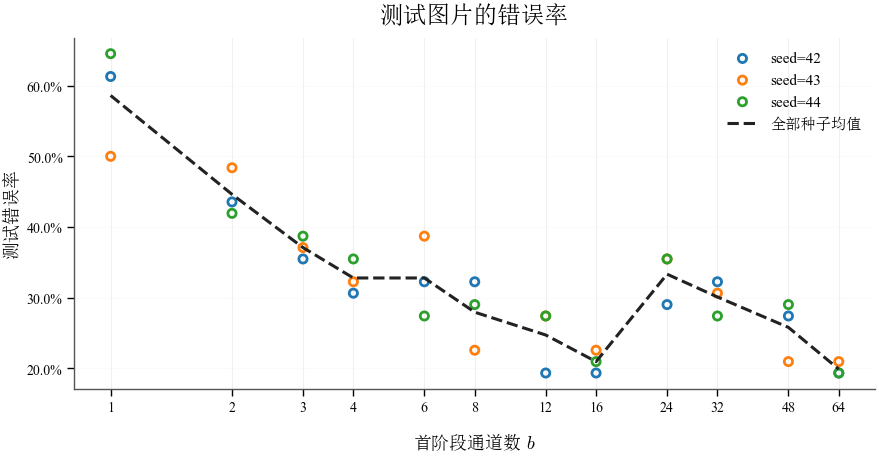

In [20]:
# ---------- 本图可改的参数 ----------
TITLE = '测试图片的错误率'
FIGSIZE = (9, 4.8)
SEEDS_TO_SHOW = SEEDS                 # 例如改成 [44]，只画一个种子
SHOW_MEAN = True                      # 均值始终是全部已完成种子的均值
X_SCALE = "log"                      # 可改成 "linear"
LINE_WIDTH = 1.6
POINT_SIZE = 5
TITLE_SIZE = 17
LABEL_SIZE = 13
TICK_SIZE = 10
COLORS = {42: "#1f77b4", 43: "#ff7f0e", 44: "#2ca02c"}
FILENAME = '01_test_error'

# ---------- 画这一张图 ----------
fig, ax = plt.subplots(figsize=FIGSIZE)

for seed in SEEDS_TO_SHOW:
    rows = results.loc[results["seed"] == seed].sort_values("width")
    # ax.plot(rows["width"], rows['test_error'], marker="o",
    #         linewidth=LINE_WIDTH, markersize=POINT_SIZE,
    #         color=COLORS.get(seed), label=f"seed={seed}")
    ax.scatter(rows['width'],rows['test_error'],marker='o',s=35,facecolors='none',edgecolors=COLORS.get(seed),linewidths=2, label=f"seed={seed}")

if SHOW_MEAN:
    ax.plot(mean_results.index, mean_results['test_error'],
            color="#222222", linestyle="--", linewidth=2.2,
            label="全部种子均值")

if X_SCALE == "log":
    ax.set_xscale("log", base=2)
ax.set_xticks(WIDTHS)
ax.set_xticklabels(WIDTHS)
# ax.set_xlabel("首阶段通道数 b", fontsize=LABEL_SIZE)
pb.mixed_label(ax,text=r"首阶段通道数$b$",size=LABEL_SIZE)
ax.set_ylabel('测试错误率', fontsize=LABEL_SIZE)
ax.set_title(TITLE, fontsize=TITLE_SIZE, pad=12)
ax.tick_params(labelsize=TICK_SIZE)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.18)
ax.legend(frameon=False, fontsize=11)
fig.tight_layout()
pb.clean_axis(ax)
if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


## 图2：测试交叉熵

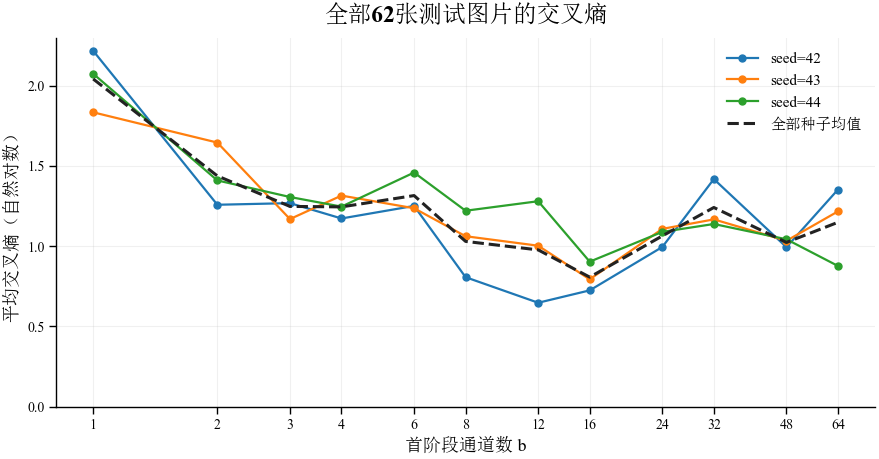

In [21]:
# ---------- 本图可改的参数 ----------
TITLE = '全部62张测试图片的交叉熵'
FIGSIZE = (9, 4.8)
SEEDS_TO_SHOW = SEEDS                 # 例如改成 [44]，只画一个种子
SHOW_MEAN = True                      # 均值始终是全部已完成种子的均值
X_SCALE = "log"                      # 可改成 "linear"
LINE_WIDTH = 1.6
POINT_SIZE = 5
TITLE_SIZE = 17
LABEL_SIZE = 13
TICK_SIZE = 10
COLORS = {42: "#1f77b4", 43: "#ff7f0e", 44: "#2ca02c"}
FILENAME = '02_test_loss'

# ---------- 画这一张图 ----------
fig, ax = plt.subplots(figsize=FIGSIZE)

for seed in SEEDS_TO_SHOW:
    rows = results.loc[results["seed"] == seed].sort_values("width")
    ax.plot(rows["width"], rows['test_loss'], marker="o",
            linewidth=LINE_WIDTH, markersize=POINT_SIZE,
            color=COLORS.get(seed), label=f"seed={seed}")

if SHOW_MEAN:
    ax.plot(mean_results.index, mean_results['test_loss'],
            color="#222222", linestyle="--", linewidth=2.2,
            label="全部种子均值")

if X_SCALE == "log":
    ax.set_xscale("log", base=2)
ax.set_xticks(WIDTHS)
ax.set_xticklabels(WIDTHS)
ax.set_xlabel("首阶段通道数 b", fontsize=LABEL_SIZE)
ax.set_ylabel('平均交叉熵（自然对数）', fontsize=LABEL_SIZE)
ax.set_title(TITLE, fontsize=TITLE_SIZE, pad=12)
ax.tick_params(labelsize=TICK_SIZE)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.18)
ax.legend(frameon=False, fontsize=11)
fig.tight_layout()

if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


## 图3：含噪训练错误率

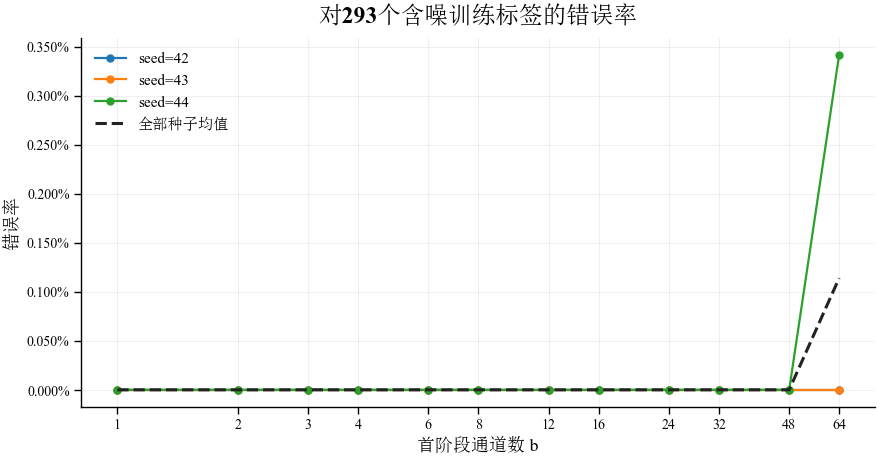

In [22]:
# ---------- 本图可改的参数 ----------
TITLE = '对293个含噪训练标签的错误率'
FIGSIZE = (9, 4.8)
SEEDS_TO_SHOW = SEEDS                 # 例如改成 [44]，只画一个种子
SHOW_MEAN = True                      # 均值始终是全部已完成种子的均值
X_SCALE = "log"                      # 可改成 "linear"
LINE_WIDTH = 1.6
POINT_SIZE = 5
TITLE_SIZE = 17
LABEL_SIZE = 13
TICK_SIZE = 10
COLORS = {42: "#1f77b4", 43: "#ff7f0e", 44: "#2ca02c"}
FILENAME = '03_train_error'

# ---------- 画这一张图 ----------
fig, ax = plt.subplots(figsize=FIGSIZE)

for seed in SEEDS_TO_SHOW:
    rows = results.loc[results["seed"] == seed].sort_values("width")
    ax.plot(rows["width"], rows['train_observed_error'], marker="o",
            linewidth=LINE_WIDTH, markersize=POINT_SIZE,
            color=COLORS.get(seed), label=f"seed={seed}")

if SHOW_MEAN:
    ax.plot(mean_results.index, mean_results['train_observed_error'],
            color="#222222", linestyle="--", linewidth=2.2,
            label="全部种子均值")

if X_SCALE == "log":
    ax.set_xscale("log", base=2)
ax.set_xticks(WIDTHS)
ax.set_xticklabels(WIDTHS)
ax.set_xlabel("首阶段通道数 b", fontsize=LABEL_SIZE)
ax.set_ylabel('错误率', fontsize=LABEL_SIZE)
ax.set_title(TITLE, fontsize=TITLE_SIZE, pad=12)
ax.tick_params(labelsize=TICK_SIZE)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.18)
ax.legend(frameon=False, fontsize=11)
fig.tight_layout()

if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


## 图4：含噪训练交叉熵

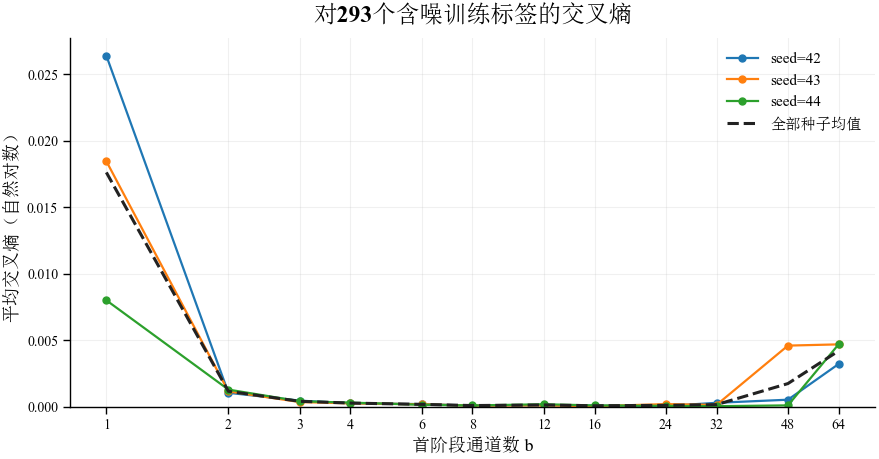

In [23]:
# ---------- 本图可改的参数 ----------
TITLE = '对293个含噪训练标签的交叉熵'
FIGSIZE = (9, 4.8)
SEEDS_TO_SHOW = SEEDS                 # 例如改成 [44]，只画一个种子
SHOW_MEAN = True                      # 均值始终是全部已完成种子的均值
X_SCALE = "log"                      # 可改成 "linear"
LINE_WIDTH = 1.6
POINT_SIZE = 5
TITLE_SIZE = 17
LABEL_SIZE = 13
TICK_SIZE = 10
COLORS = {42: "#1f77b4", 43: "#ff7f0e", 44: "#2ca02c"}
FILENAME = '04_train_loss'

# ---------- 画这一张图 ----------
fig, ax = plt.subplots(figsize=FIGSIZE)

for seed in SEEDS_TO_SHOW:
    rows = results.loc[results["seed"] == seed].sort_values("width")
    ax.plot(rows["width"], rows['train_observed_loss'], marker="o",
            linewidth=LINE_WIDTH, markersize=POINT_SIZE,
            color=COLORS.get(seed), label=f"seed={seed}")

if SHOW_MEAN:
    ax.plot(mean_results.index, mean_results['train_observed_loss'],
            color="#222222", linestyle="--", linewidth=2.2,
            label="全部种子均值")

if X_SCALE == "log":
    ax.set_xscale("log", base=2)
ax.set_xticks(WIDTHS)
ax.set_xticklabels(WIDTHS)
ax.set_xlabel("首阶段通道数 b", fontsize=LABEL_SIZE)
ax.set_ylabel('平均交叉熵（自然对数）', fontsize=LABEL_SIZE)
ax.set_title(TITLE, fontsize=TITLE_SIZE, pad=12)
ax.tick_params(labelsize=TICK_SIZE)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.18)
ax.legend(frameon=False, fontsize=11)
fig.tight_layout()

if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


## 图片对照的修改位置

下面每个单元格都完整绘制一张图。

- `widths`：显示哪些宽度；`sample_ids`：显示哪些测试图片；`seed`：用哪个种子。
- `FIGSIZE`：整张图大小；`NAME_SIZE`、`CONFIDENCE_SIZE`：预测角色和置信度字号。
- `GOOD_*`、`BAD_*`：判对与判错的背景、文字颜色。
- `fig.subplots_adjust(...)`：图与图之间的间距。
- 图片显示模型实际输入；底部判对数只对应所显示的图片。

每个单元格最后分别保存和显示本张图。

## 图5：9列预测对照

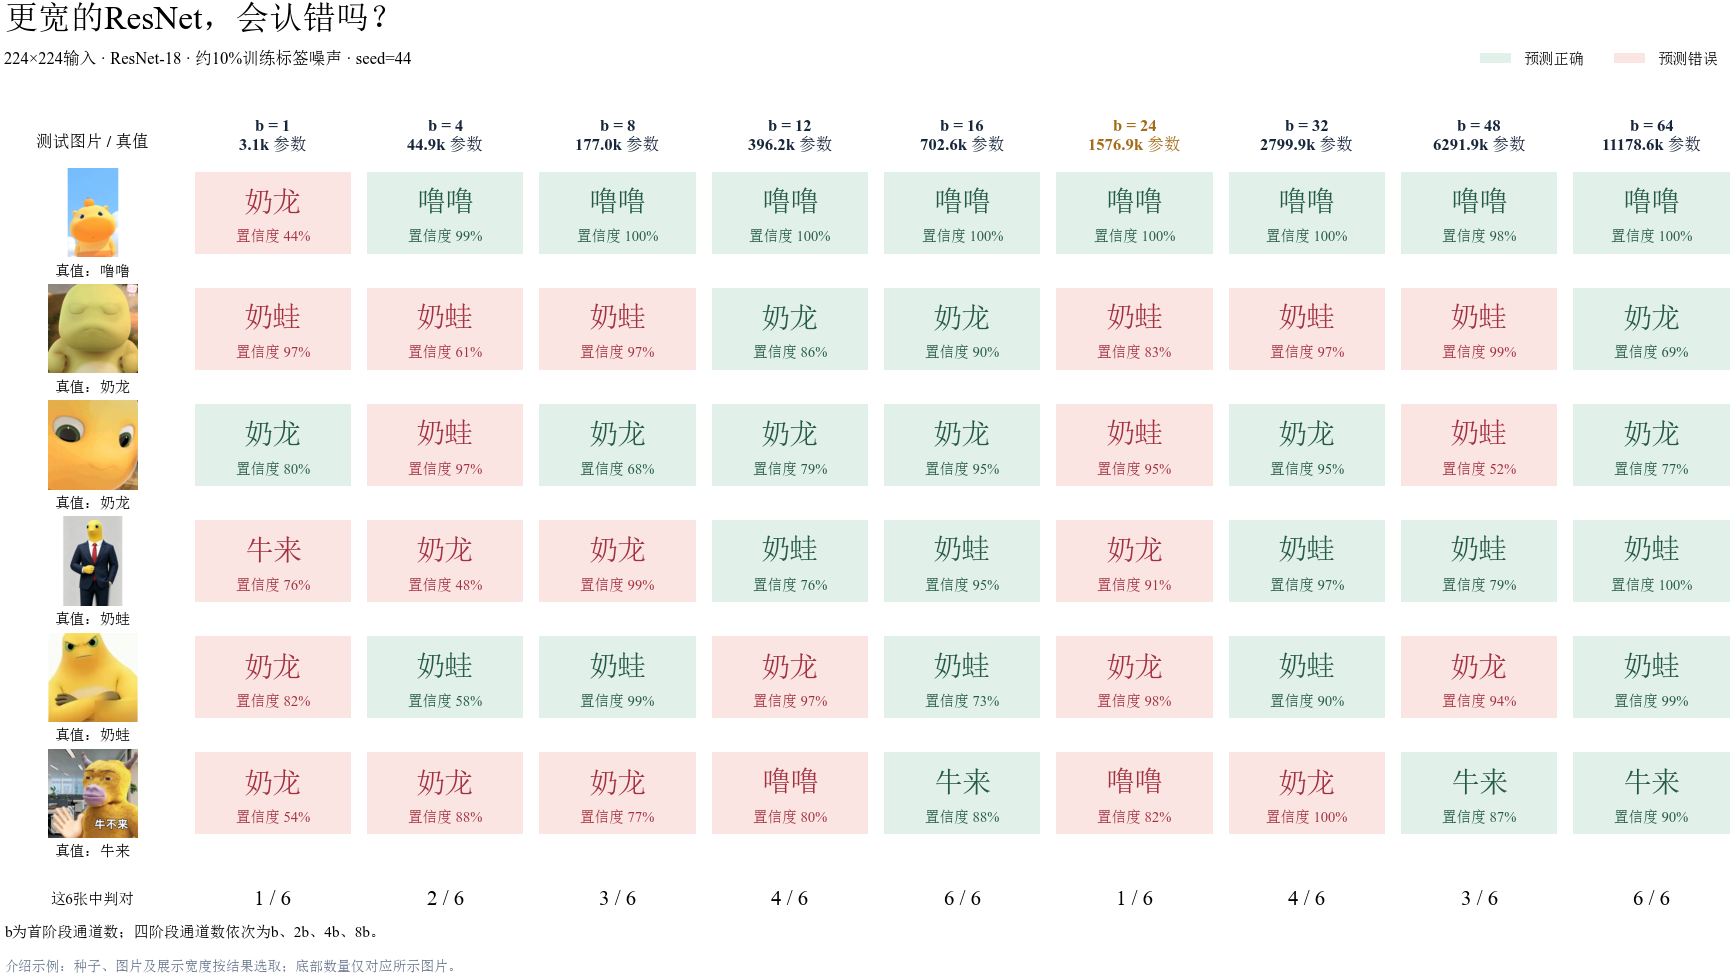

In [24]:
# ---------- 本图可改的参数 ----------
widths = [1, 4, 8, 12, 16, 24, 32, 48, 64]
sample_ids = SAMPLE_IDS.copy()       # 也可直接填测试图片ID列表
seed = SELECTED_SEED
TITLE = "更宽的ResNet，会认错吗？"
FIGSIZE = (18, 10)
NAME_SIZE = 21
CONFIDENCE_SIZE = 10.5
HEADER_SIZE = 12
GOOD_BG, GOOD_TEXT = "#e1f0e9", "#245947"
BAD_BG, BAD_TEXT = "#fae5e3", "#a3303f"
PEAK_WIDTH = 24                       # 高亮这一列的表头；设为None可取消
PEAK_COLOR = "#a36b18"
FILENAME = '05_predictions_9models'

# ---------- 建立行列：第一列放图片，其余列放预测 ----------
n_rows, n_columns = len(sample_ids), len(widths)
fig, axes = plt.subplots(n_rows, n_columns + 1, figsize=FIGSIZE, squeeze=False,
                         gridspec_kw={"width_ratios": [1.1] + [1] * n_columns})
fig.subplots_adjust(left=0.025, right=0.985, top=0.82, bottom=0.15,
                    wspace=0.07, hspace=0.30)
fig.suptitle(TITLE, fontsize=24, x=0.025, ha="left", y=0.985)
fig.text(0.025, 0.925,
         f"224×224输入 · ResNet-18 · 约10%训练标签噪声 · seed={seed}", fontsize=12)
fig.legend(handles=[Patch(facecolor=GOOD_BG, label="预测正确"),
                    Patch(facecolor=BAD_BG, label="预测错误")],
           loc="upper right", bbox_to_anchor=(0.985, 0.95),
           ncol=2, frameon=False, fontsize=11)

# ---------- 第一列：图片与真实角色 ----------
for row_number, sample_id in enumerate(sample_ids):
    ax = axes[row_number, 0]
    ax.imshow(TEST_IMAGES[sample_id])
    ax.axis("off")
    ax.text(0.5, -0.07, f"真值：{TRUE_ROLES[sample_id]}",
            transform=ax.transAxes, ha="center", va="top", fontsize=11)
axes[0, 0].set_title("测试图片 / 真值", fontsize=HEADER_SIZE, pad=16)

# ---------- 其余列：每个宽度的预测角色与置信度 ----------
correct_counts = []
for column_number, width in enumerate(widths, start=1):
    count = 0
    for row_number, sample_id in enumerate(sample_ids):
        prediction = prediction_table.loc[(seed, sample_id, width)]
        correct = bool(prediction["correct"])
        count += int(correct)
        background = GOOD_BG if correct else BAD_BG
        text_color = GOOD_TEXT if correct else BAD_TEXT
        ax = axes[row_number, column_number]
        ax.axis("off")
        ax.add_patch(Rectangle((0.015, 0.04), 0.97, 0.92,
                               transform=ax.transAxes, facecolor=background, edgecolor="none"))
        ax.text(0.5, 0.61, ROLE_NAMES[prediction["predicted_class"]],
                transform=ax.transAxes, ha="center", va="center",
                fontsize=NAME_SIZE, color=text_color)
        ax.text(0.5, 0.24, f"置信度 {prediction['confidence']:.0%}",
                transform=ax.transAxes, ha="center", va="center",
                fontsize=CONFIDENCE_SIZE, color=text_color)

    parameter_count = parameter_counts.loc[(seed, width)]
    header_color = PEAK_COLOR if width == PEAK_WIDTH else "#18263b"
    axes[0, column_number].set_title(f"b = {width}\n{parameter_count / 1000:.1f}k 参数",
                                     fontsize=HEADER_SIZE, color=header_color, pad=14)
    axes[-1, column_number].text(0.5, -0.68, f"{count} / {n_rows}",
                                 transform=axes[-1, column_number].transAxes,
                                 ha="center", va="center", fontsize=15)
    correct_counts.append(count)

# ---------- 底部说明 ----------
axes[-1, 0].text(0.5, -0.68, f"这{n_rows}张中判对",
                 transform=axes[-1, 0].transAxes, ha="center", va="center", fontsize=11)
fig.text(0.025, 0.052, "b为首阶段通道数；四阶段通道数依次为b、2b、4b、8b。", fontsize=11)
fig.text(0.025, 0.018,
         "介绍示例：种子、图片及展示宽度按结果选取；底部数量仅对应所示图片。",
         fontsize=10, color="#607087")

# ---------- 保存和显示这一张图 ----------
if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


## 图6：7列预测对照

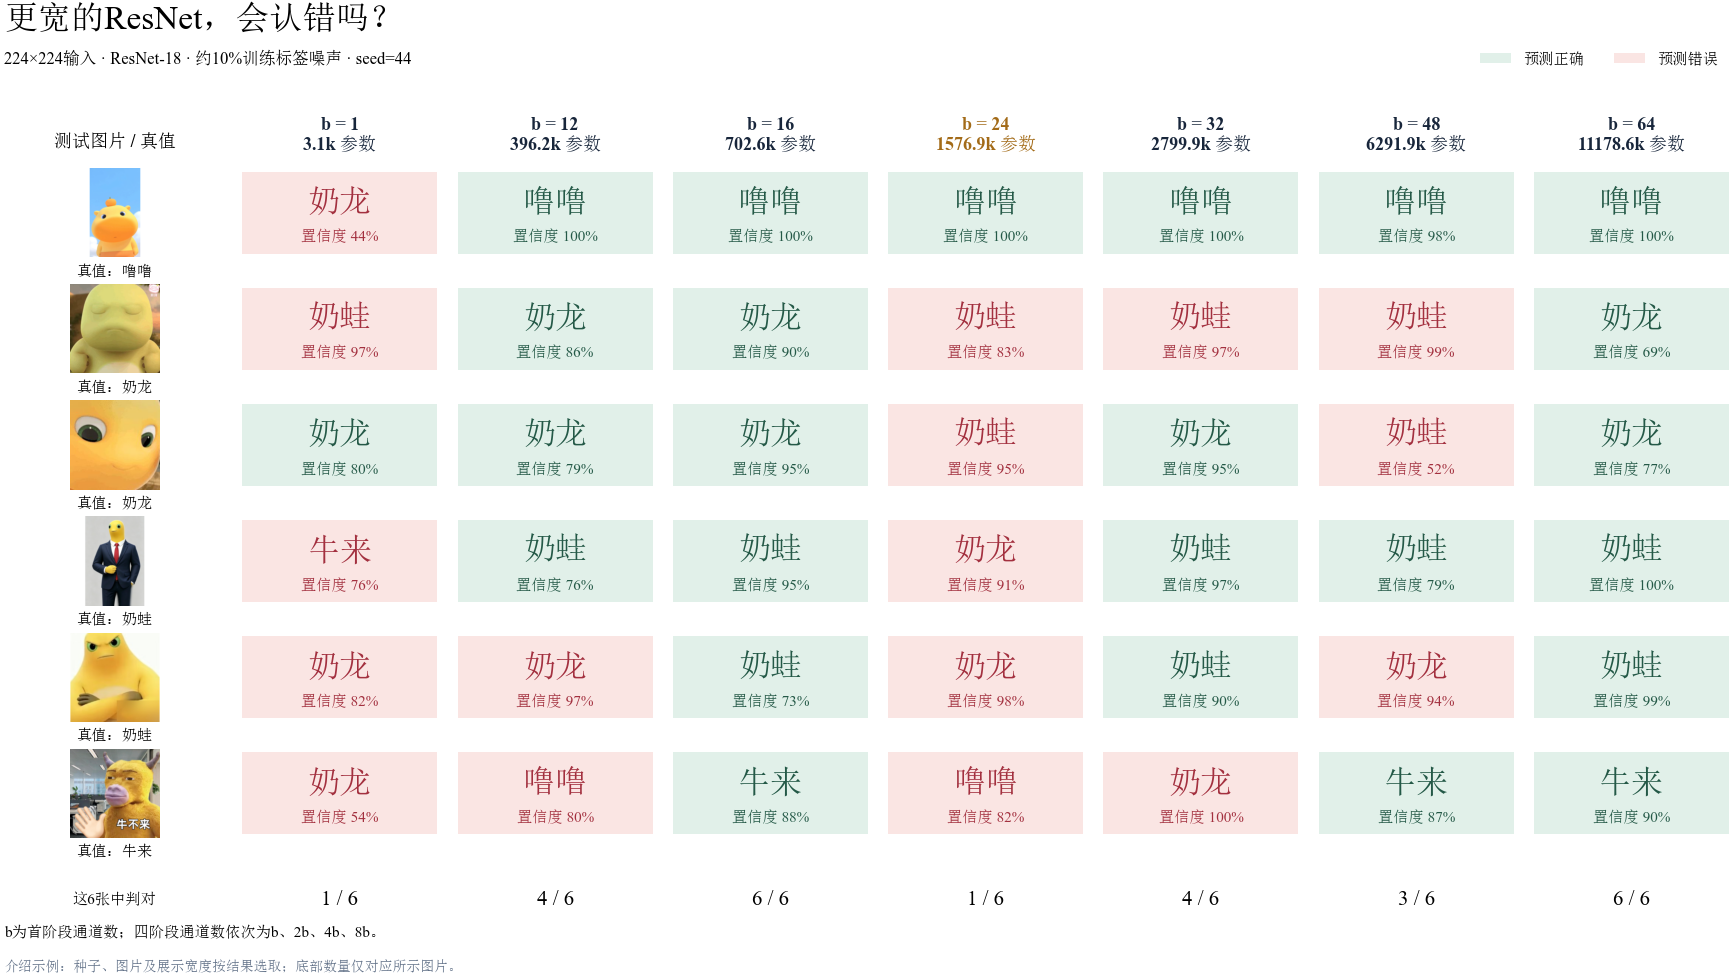

In [25]:
# ---------- 本图可改的参数 ----------
widths = [1, 12, 16, 24, 32, 48, 64]
sample_ids = SAMPLE_IDS.copy()       # 也可直接填测试图片ID列表
seed = SELECTED_SEED
TITLE = "更宽的ResNet，会认错吗？"
FIGSIZE = (18, 10)
NAME_SIZE = 23
CONFIDENCE_SIZE = 11
HEADER_SIZE = 13
GOOD_BG, GOOD_TEXT = "#e1f0e9", "#245947"
BAD_BG, BAD_TEXT = "#fae5e3", "#a3303f"
PEAK_WIDTH = 24                       # 高亮这一列的表头；设为None可取消
PEAK_COLOR = "#a36b18"
FILENAME = '06_predictions_7models'

# ---------- 建立行列：第一列放图片，其余列放预测 ----------
n_rows, n_columns = len(sample_ids), len(widths)
fig, axes = plt.subplots(n_rows, n_columns + 1, figsize=FIGSIZE, squeeze=False,
                         gridspec_kw={"width_ratios": [1.1] + [1] * n_columns})
fig.subplots_adjust(left=0.025, right=0.985, top=0.82, bottom=0.15,
                    wspace=0.07, hspace=0.30)
fig.suptitle(TITLE, fontsize=24, x=0.025, ha="left", y=0.985)
fig.text(0.025, 0.925,
         f"224×224输入 · ResNet-18 · 约10%训练标签噪声 · seed={seed}", fontsize=12)
fig.legend(handles=[Patch(facecolor=GOOD_BG, label="预测正确"),
                    Patch(facecolor=BAD_BG, label="预测错误")],
           loc="upper right", bbox_to_anchor=(0.985, 0.95),
           ncol=2, frameon=False, fontsize=11)

# ---------- 第一列：图片与真实角色 ----------
for row_number, sample_id in enumerate(sample_ids):
    ax = axes[row_number, 0]
    ax.imshow(TEST_IMAGES[sample_id])
    ax.axis("off")
    ax.text(0.5, -0.07, f"真值：{TRUE_ROLES[sample_id]}",
            transform=ax.transAxes, ha="center", va="top", fontsize=11)
axes[0, 0].set_title("测试图片 / 真值", fontsize=HEADER_SIZE, pad=16)

# ---------- 其余列：每个宽度的预测角色与置信度 ----------
correct_counts = []
for column_number, width in enumerate(widths, start=1):
    count = 0
    for row_number, sample_id in enumerate(sample_ids):
        prediction = prediction_table.loc[(seed, sample_id, width)]
        correct = bool(prediction["correct"])
        count += int(correct)
        background = GOOD_BG if correct else BAD_BG
        text_color = GOOD_TEXT if correct else BAD_TEXT
        ax = axes[row_number, column_number]
        ax.axis("off")
        ax.add_patch(Rectangle((0.015, 0.04), 0.97, 0.92,
                               transform=ax.transAxes, facecolor=background, edgecolor="none"))
        ax.text(0.5, 0.61, ROLE_NAMES[prediction["predicted_class"]],
                transform=ax.transAxes, ha="center", va="center",
                fontsize=NAME_SIZE, color=text_color)
        ax.text(0.5, 0.24, f"置信度 {prediction['confidence']:.0%}",
                transform=ax.transAxes, ha="center", va="center",
                fontsize=CONFIDENCE_SIZE, color=text_color)

    parameter_count = parameter_counts.loc[(seed, width)]
    header_color = PEAK_COLOR if width == PEAK_WIDTH else "#18263b"
    axes[0, column_number].set_title(f"b = {width}\n{parameter_count / 1000:.1f}k 参数",
                                     fontsize=HEADER_SIZE, color=header_color, pad=14)
    axes[-1, column_number].text(0.5, -0.68, f"{count} / {n_rows}",
                                 transform=axes[-1, column_number].transAxes,
                                 ha="center", va="center", fontsize=15)
    correct_counts.append(count)

# ---------- 底部说明 ----------
axes[-1, 0].text(0.5, -0.68, f"这{n_rows}张中判对",
                 transform=axes[-1, 0].transAxes, ha="center", va="center", fontsize=11)
fig.text(0.025, 0.052, "b为首阶段通道数；四阶段通道数依次为b、2b、4b、8b。", fontsize=11)
fig.text(0.025, 0.018,
         "介绍示例：种子、图片及展示宽度按结果选取；底部数量仅对应所示图片。",
         fontsize=10, color="#607087")

# ---------- 保存和显示这一张图 ----------
if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


## 图7：完整12列预测对照

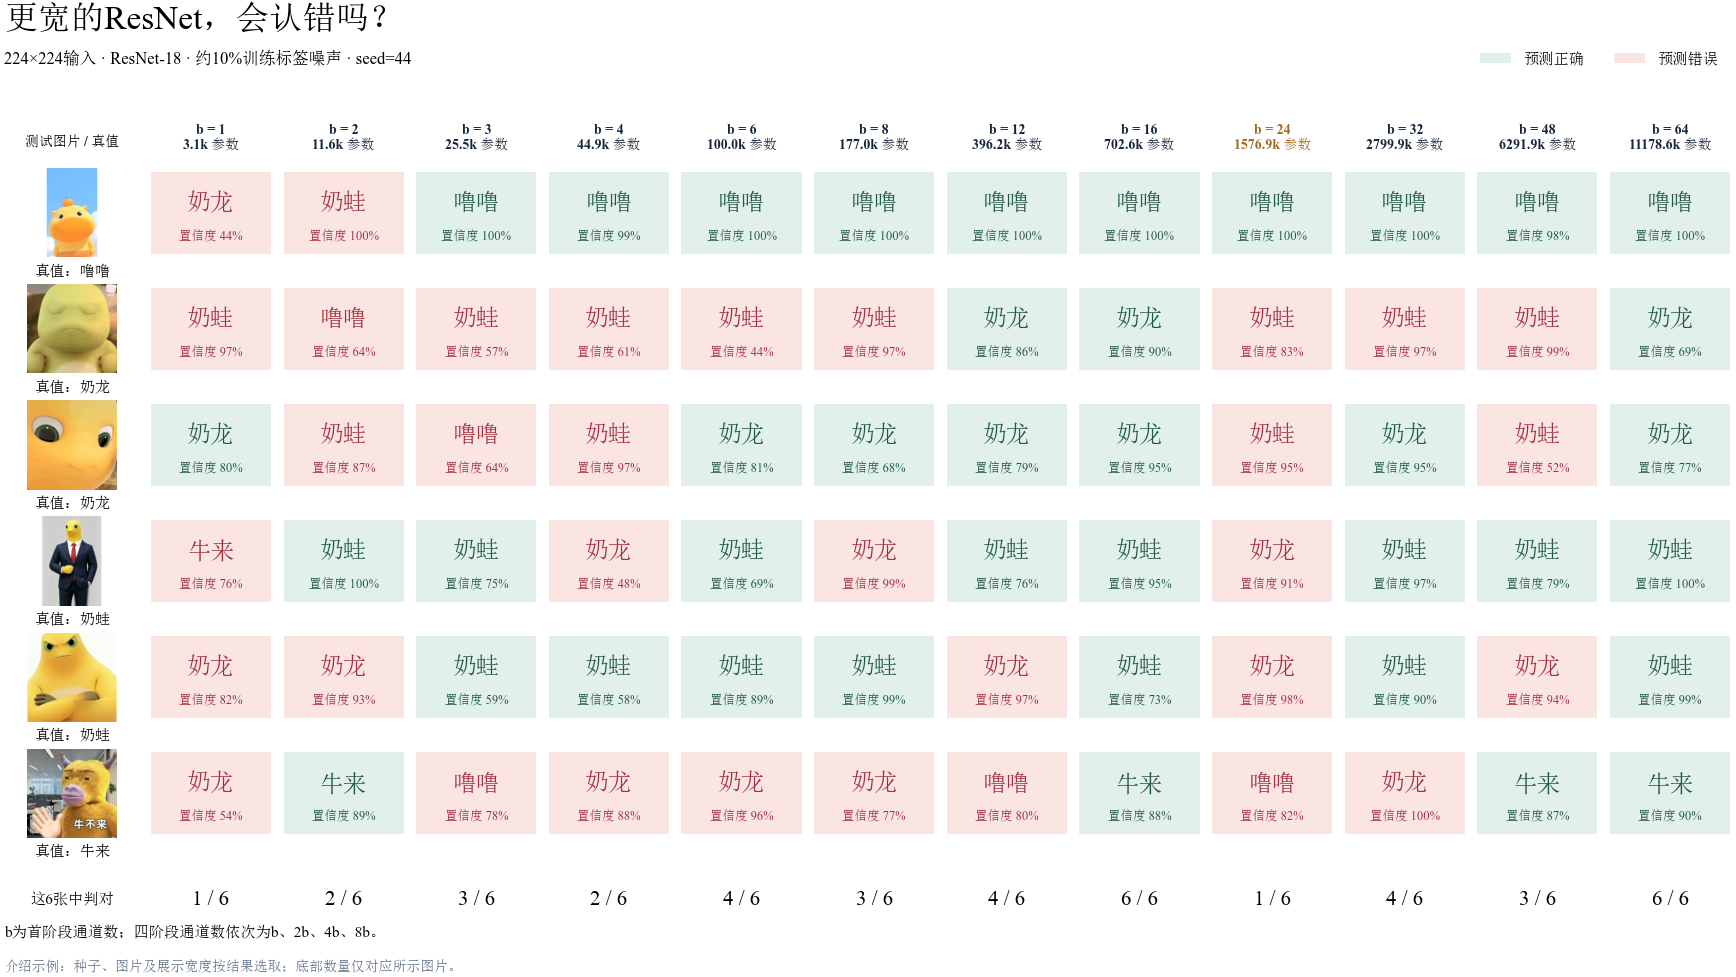

In [26]:
# ---------- 本图可改的参数 ----------
widths = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]
sample_ids = SAMPLE_IDS.copy()       # 也可直接填测试图片ID列表
seed = SELECTED_SEED
TITLE = "更宽的ResNet，会认错吗？"
FIGSIZE = (18, 10)
NAME_SIZE = 17
CONFIDENCE_SIZE = 9
HEADER_SIZE = 10
GOOD_BG, GOOD_TEXT = "#e1f0e9", "#245947"
BAD_BG, BAD_TEXT = "#fae5e3", "#a3303f"
PEAK_WIDTH = 24                       # 高亮这一列的表头；设为None可取消
PEAK_COLOR = "#a36b18"
FILENAME = '07_predictions_all12models'

# ---------- 建立行列：第一列放图片，其余列放预测 ----------
n_rows, n_columns = len(sample_ids), len(widths)
fig, axes = plt.subplots(n_rows, n_columns + 1, figsize=FIGSIZE, squeeze=False,
                         gridspec_kw={"width_ratios": [1.1] + [1] * n_columns})
fig.subplots_adjust(left=0.025, right=0.985, top=0.82, bottom=0.15,
                    wspace=0.07, hspace=0.30)
fig.suptitle(TITLE, fontsize=24, x=0.025, ha="left", y=0.985)
fig.text(0.025, 0.925,
         f"224×224输入 · ResNet-18 · 约10%训练标签噪声 · seed={seed}", fontsize=12)
fig.legend(handles=[Patch(facecolor=GOOD_BG, label="预测正确"),
                    Patch(facecolor=BAD_BG, label="预测错误")],
           loc="upper right", bbox_to_anchor=(0.985, 0.95),
           ncol=2, frameon=False, fontsize=11)

# ---------- 第一列：图片与真实角色 ----------
for row_number, sample_id in enumerate(sample_ids):
    ax = axes[row_number, 0]
    ax.imshow(TEST_IMAGES[sample_id])
    ax.axis("off")
    ax.text(0.5, -0.07, f"真值：{TRUE_ROLES[sample_id]}",
            transform=ax.transAxes, ha="center", va="top", fontsize=11)
axes[0, 0].set_title("测试图片 / 真值", fontsize=HEADER_SIZE, pad=16)

# ---------- 其余列：每个宽度的预测角色与置信度 ----------
correct_counts = []
for column_number, width in enumerate(widths, start=1):
    count = 0
    for row_number, sample_id in enumerate(sample_ids):
        prediction = prediction_table.loc[(seed, sample_id, width)]
        correct = bool(prediction["correct"])
        count += int(correct)
        background = GOOD_BG if correct else BAD_BG
        text_color = GOOD_TEXT if correct else BAD_TEXT
        ax = axes[row_number, column_number]
        ax.axis("off")
        ax.add_patch(Rectangle((0.015, 0.04), 0.97, 0.92,
                               transform=ax.transAxes, facecolor=background, edgecolor="none"))
        ax.text(0.5, 0.61, ROLE_NAMES[prediction["predicted_class"]],
                transform=ax.transAxes, ha="center", va="center",
                fontsize=NAME_SIZE, color=text_color)
        ax.text(0.5, 0.24, f"置信度 {prediction['confidence']:.0%}",
                transform=ax.transAxes, ha="center", va="center",
                fontsize=CONFIDENCE_SIZE, color=text_color)

    parameter_count = parameter_counts.loc[(seed, width)]
    header_color = PEAK_COLOR if width == PEAK_WIDTH else "#18263b"
    axes[0, column_number].set_title(f"b = {width}\n{parameter_count / 1000:.1f}k 参数",
                                     fontsize=HEADER_SIZE, color=header_color, pad=14)
    axes[-1, column_number].text(0.5, -0.68, f"{count} / {n_rows}",
                                 transform=axes[-1, column_number].transAxes,
                                 ha="center", va="center", fontsize=15)
    correct_counts.append(count)

# ---------- 底部说明 ----------
axes[-1, 0].text(0.5, -0.68, f"这{n_rows}张中判对",
                 transform=axes[-1, 0].transAxes, ha="center", va="center", fontsize=11)
fig.text(0.025, 0.052, "b为首阶段通道数；四阶段通道数依次为b、2b、4b、8b。", fontsize=11)
fig.text(0.025, 0.018,
         "介绍示例：种子、图片及展示宽度按结果选取；底部数量仅对应所示图片。",
         fontsize=10, color="#607087")

# ---------- 保存和显示这一张图 ----------
if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight")
plt.show()
plt.close(fig)


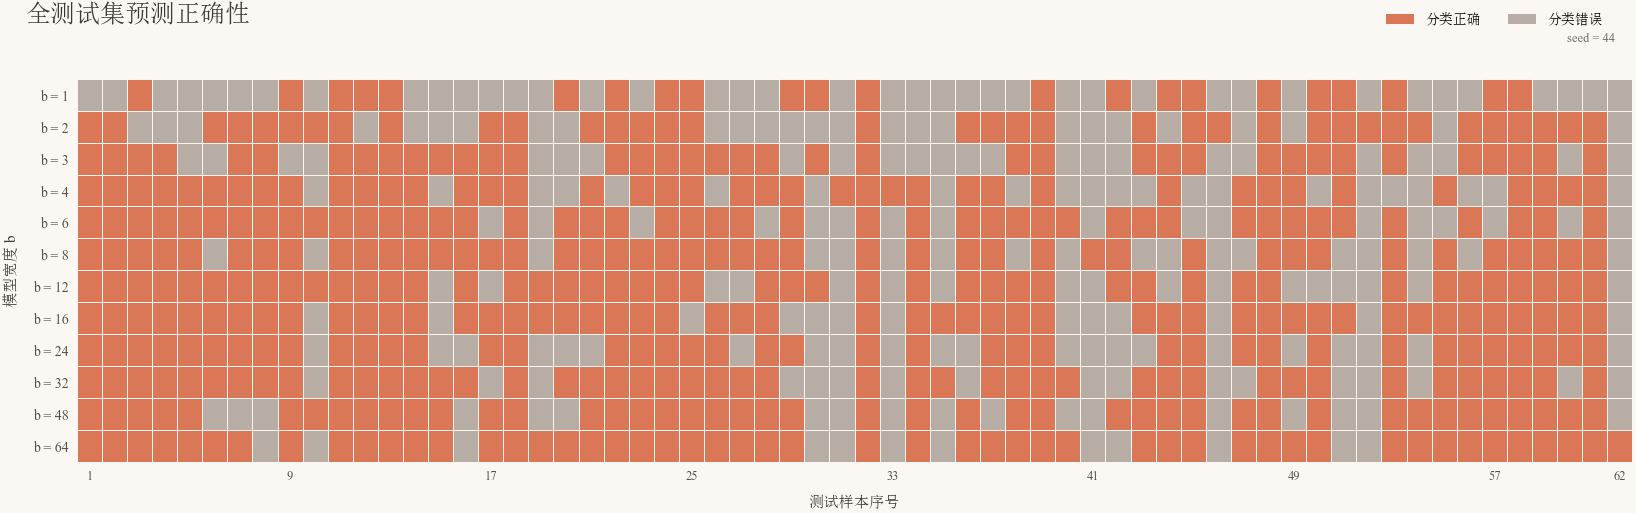

In [27]:
from matplotlib.colors import ListedColormap, BoundaryNorm
# ---------- 全测试集预测正确性热力图 ----------
widths = WIDTHS
sample_ids = test_rows["sample_id"].tolist()  # 按 splits.csv 的测试集顺序
seed = SELECTED_SEED
FILENAME = "07_predictions_calendar"

# Claude 风格暖色：橙色表示正确，暖灰色表示错误。
CORRECT_COLOR = "#D97757"
INCORRECT_COLOR = "#B7ADA4"
CANVAS_COLOR = "#FBF8F4"
GRID_COLOR = "#FBF8F4"

# 行为模型宽度 b，列为全部测试样本；格子内只编码对错，不写文字。
correctness = np.zeros((len(widths), len(sample_ids)), dtype=np.int8)
for row, width in enumerate(widths):
    for column, sample_id in enumerate(sample_ids):
        correctness[row, column] = int(
            bool(prediction_table.loc[(seed, sample_id, width), "correct"])
        )

cmap = ListedColormap([INCORRECT_COLOR, CORRECT_COLOR])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)
fig, ax = plt.subplots(figsize=(17, 5.8))
fig.patch.set_facecolor(CANVAS_COLOR)
ax.set_facecolor(CANVAS_COLOR)

ax.pcolormesh(
    np.arange(len(sample_ids) + 1),
    np.arange(len(widths) + 1),
    correctness,
    cmap=cmap,
    norm=norm,
    edgecolors=GRID_COLOR,
    linewidth=0.7,
    antialiased=True,
    shading="flat",
)

ax.set_xlim(0, len(sample_ids))
ax.set_ylim(len(widths), 0)  # b 较小的模型显示在上方
ax.set_yticks(np.arange(len(widths)) + 0.5)
ax.set_yticklabels([f"b = {width}" for width in widths], fontsize=10)

# 稀疏标注样本序号，避免 64 个刻度挤在一起；每个样本仍有独立色块。
sample_ticks = list(range(0, len(sample_ids), 8))
if sample_ids and sample_ticks[-1] != len(sample_ids) - 1:
    sample_ticks.append(len(sample_ids) - 1)
ax.set_xticks([index + 0.5 for index in sample_ticks])
ax.set_xticklabels([str(index + 1) for index in sample_ticks], fontsize=9)
ax.set_xlabel("测试样本序号", fontsize=11, labelpad=9, color="#3D3935")
ax.set_ylabel("模型宽度 b", fontsize=11, labelpad=10, color="#3D3935")
ax.tick_params(axis="both", length=0, colors="#554D47", pad=6)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.suptitle("全测试集预测正确性", x=0.045, y=0.97, ha="left",
             fontsize=18, color="#3D3935", fontweight="semibold")
legend_handles = [
    Patch(facecolor=CORRECT_COLOR, edgecolor="none", label="分类正确"),
    Patch(facecolor=INCORRECT_COLOR, edgecolor="none", label="分类错误"),
]
fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(0.98, 0.975),
           ncol=2, frameon=False, fontsize=10)
fig.text(0.98, 0.91, f"seed = {seed}", ha="right", va="center",
         fontsize=9, color="#756B64")
fig.subplots_adjust(left=0.075, right=0.99, top=0.84, bottom=0.18)

if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight",
                    facecolor=fig.get_facecolor())
plt.show()
plt.close(fig)


In [28]:
unstable = (
    predictions.groupby(["width", "sample_id"])["predicted_label"]
    .nunique()
    .gt(1)
)
unstable_rate = unstable.groupby(level="width").mean()

In [29]:
unstable_rate

width
1     0.903226
2     0.709677
3     0.500000
4     0.483871
6     0.467742
8     0.403226
12    0.354839
16    0.322581
24    0.467742
32    0.306452
48    0.306452
64    0.193548
Name: predicted_label, dtype: float64

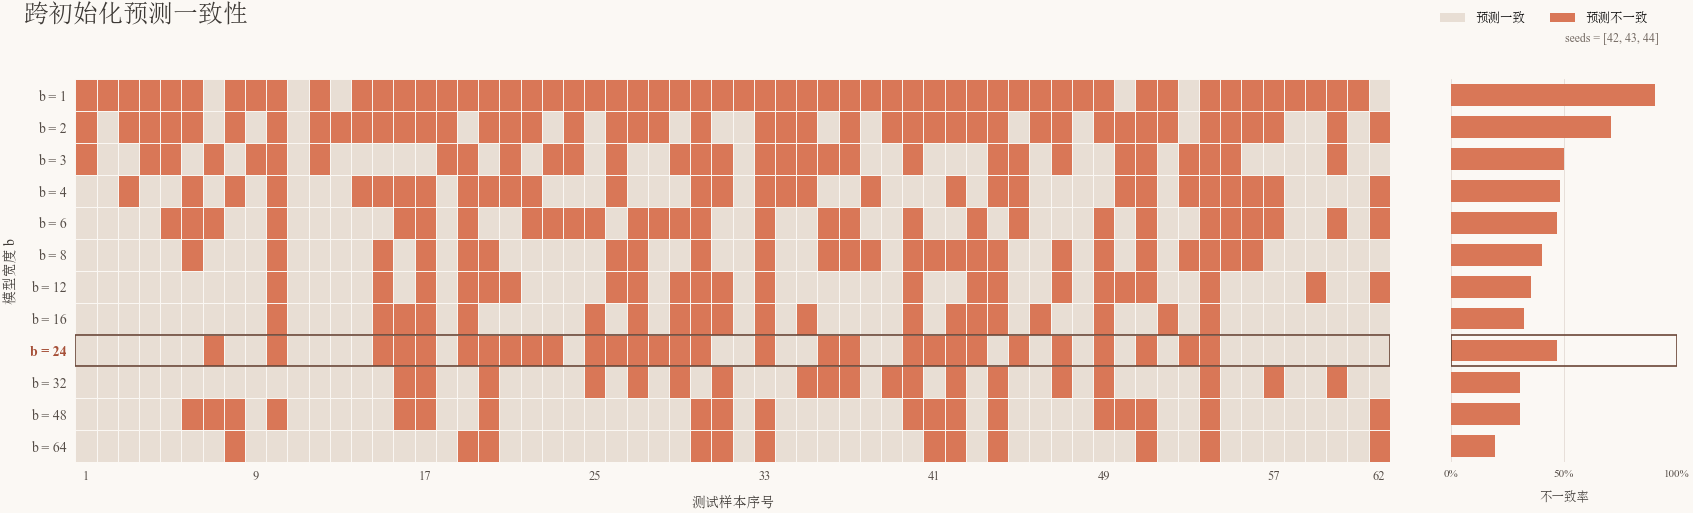

In [30]:
# ---------- 跨初始化预测一致性热力图 ----------
widths = WIDTHS
sample_ids = test_rows["sample_id"].tolist()  # 按 splits.csv 的测试集顺序
FILENAME = "07_predictions_seed_stability"

# Claude 风格暖色：浅米色表示一致，暖橙色表示不同初始化给出不同类别。
STABLE_COLOR = "#E8DED4"
UNSTABLE_COLOR = "#D97757"
CANVAS_COLOR = "#FBF8F4"
GRID_COLOR = "#FBF8F4"

# 每格汇总同一 (b, sample) 下所有 seed 的预测类别。
# 0 = 所有初始化一致；1 = 至少两个初始化预测不同。
unstable = (
    predictions.groupby(["width", "sample_id"])["predicted_label"]
    .nunique()
    .gt(1)
    .unstack("sample_id")
    .reindex(index=widths, columns=sample_ids)
)
unstable_matrix = unstable.to_numpy(dtype=np.int8)
unstable_rate = unstable.mean(axis=1)

cmap = ListedColormap([STABLE_COLOR, UNSTABLE_COLOR])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)
n_samples = len(sample_ids)
n_widths = len(widths)
fig, (ax, rate_ax) = plt.subplots(
    1, 2, figsize=(17.5, 5.8), sharey=True,
    gridspec_kw={"width_ratios": [14, 2.4], "wspace": 0.08},
)
fig.patch.set_facecolor(CANVAS_COLOR)
ax.set_facecolor(CANVAS_COLOR)
rate_ax.set_facecolor(CANVAS_COLOR)

ax.pcolormesh(
    np.arange(n_samples + 1),
    np.arange(n_widths + 1),
    unstable_matrix,
    cmap=cmap,
    norm=norm,
    edgecolors=GRID_COLOR,
    linewidth=0.7,
    antialiased=True,
    shading="flat",
)
ax.set_xlim(0, n_samples)
ax.set_ylim(n_widths, 0)  # b 较小的模型显示在上方
ax.set_yticks(np.arange(n_widths) + 0.5)
ax.set_yticklabels([f"b = {width}" for width in widths], fontsize=10)

# 稀疏标注样本序号；每个样本仍有独立色格。
sample_ticks = list(range(0, n_samples, 8))
if sample_ids and sample_ticks[-1] != n_samples - 1:
    sample_ticks.append(n_samples - 1)
ax.set_xticks([index + 0.5 for index in sample_ticks])
ax.set_xticklabels([str(index + 1) for index in sample_ticks], fontsize=9)
ax.set_xlabel("测试样本序号", fontsize=10, labelpad=9, color="#3D3935")
ax.set_ylabel("模型宽度 b", fontsize=10, labelpad=9, color="#3D3935")
ax.tick_params(axis="both", length=0, colors="#554D47", pad=6)
for spine in ax.spines.values():
    spine.set_visible(False)

# 右侧汇总：每个 b 下预测不一致的测试样本比例。
row_centers = np.arange(n_widths) + 0.5
rate_ax.barh(row_centers, unstable_rate.to_numpy(), height=0.68,
             color=UNSTABLE_COLOR, edgecolor="none")
rate_ax.set_xlim(0, 1)
rate_ax.set_ylim(n_widths, 0)
rate_ax.set_yticks(row_centers)
rate_ax.tick_params(axis="y", left=False, labelleft=False)
rate_ax.set_xticks([0, 0.5, 1])
rate_ax.xaxis.set_major_formatter(PercentFormatter(1))
rate_ax.set_xlabel("不一致率", fontsize=9, labelpad=8, color="#3D3935")
rate_ax.tick_params(axis="x", length=0, labelsize=8, colors="#554D47", pad=5)
rate_ax.grid(axis="x", color="#D9CFC6", linewidth=0.6, alpha=0.7)
rate_ax.set_axisbelow(True)
for spine in rate_ax.spines.values():
    spine.set_visible(False)

# 突出 b=24 阈值行。
if 24 in widths:
    row = widths.index(24)
    ax.add_patch(Rectangle((0, row), n_samples, 1, fill=False,
                           edgecolor="#6B4738", linewidth=1.2, zorder=5))
    rate_ax.add_patch(Rectangle((0, row), 1, 1, fill=False,
                                edgecolor="#6B4738", linewidth=1.2, zorder=5))
    ax.get_yticklabels()[row].set_fontweight("bold")
    ax.get_yticklabels()[row].set_color("#A65038")

fig.suptitle("跨初始化预测一致性", x=0.045, y=0.97, ha="left",
             fontsize=18, color="#3D3935", fontweight="semibold")
legend_handles = [
    Patch(facecolor=STABLE_COLOR, edgecolor="none", label="预测一致"),
    Patch(facecolor=UNSTABLE_COLOR, edgecolor="none", label="预测不一致"),
]
fig.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(0.98, 0.975),
           ncol=2, frameon=False, fontsize=9)
fig.text(0.98, 0.91, f"seeds = {SEEDS}", ha="right", va="center",
         fontsize=8.5, color="#756B64")
fig.subplots_adjust(left=0.075, right=0.99, top=0.84, bottom=0.18)

if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(OUTPUT_DIR / f"{FILENAME}.{extension}", dpi=DPI, bbox_inches="tight",
                    facecolor=fig.get_facecolor())
plt.show()
plt.close(fig)


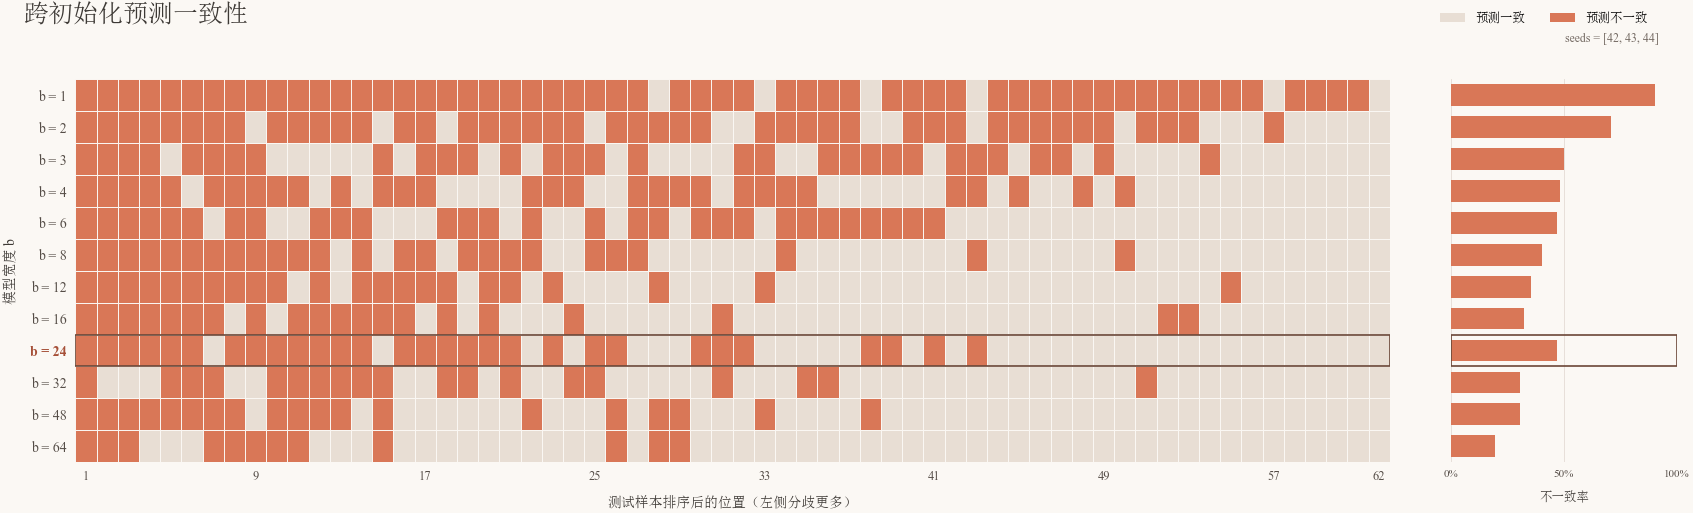

In [32]:

# ---------- 跨初始化预测一致性热力图 ----------
widths = list(WIDTHS)
sample_ids = test_rows["sample_id"].tolist()
FILENAME = "07_predictions_seed_stability"

# ---------- 风格参数：保留原版 ----------
STABLE_COLOR = "#E8DED4"
UNSTABLE_COLOR = "#D97757"
CANVAS_COLOR = "#FBF8F4"
GRID_COLOR = "#FBF8F4"
TEXT_COLOR = "#3D3935"
MUTED_COLOR = "#756B64"

FIGSIZE = (17.5, 5.8)

# ---------- 计算预测不一致情况 ----------
# 0 = 所有初始化预测一致
# 1 = 至少两个初始化预测不同

unstable = (
    predictions.groupby(["width", "sample_id"])["predicted_label"]
    .nunique()
    .gt(1)
    .unstack("sample_id")
    .reindex(index=widths, columns=sample_ids)
)

# 确保每个宽度、每个样本都有预测数据
if unstable.isna().any().any():
    raise ValueError("部分宽度或样本缺少预测数据")

# ---------- 新增：按样本预测分歧次数排序 ----------
# 每个样本在多少种宽度下出现了预测分歧
sample_instability = unstable.sum(axis=0)

# 分歧次数多的排在左边，稳定的排在右边
# stable 保证次数相同时维持原始顺序
sorted_samples = (
    sample_instability
    .sort_values(ascending=False, kind="stable")
    .index
)

unstable = unstable.loc[:, sorted_samples]

# 转换为绘图矩阵
unstable_matrix = unstable.to_numpy(dtype=np.int8)

# 每个宽度下预测不一致的样本比例
unstable_rate = unstable.mean(axis=1)

n_samples = len(sorted_samples)
n_widths = len(widths)

# ---------- 颜色映射 ----------
cmap = ListedColormap([
    STABLE_COLOR,
    UNSTABLE_COLOR
])

norm = BoundaryNorm(
    [-0.5, 0.5, 1.5],
    cmap.N
)

# ---------- 创建画布 ----------
fig, (ax, rate_ax) = plt.subplots(
    1, 2,
    figsize=FIGSIZE,
    sharey=True,
    gridspec_kw={
        "width_ratios": [14, 2.4],
        "wspace": 0.08
    }
)

fig.patch.set_facecolor(CANVAS_COLOR)
ax.set_facecolor(CANVAS_COLOR)
rate_ax.set_facecolor(CANVAS_COLOR)

# ---------- 左侧热力图 ----------
ax.pcolormesh(
    np.arange(n_samples + 1),
    np.arange(n_widths + 1),
    unstable_matrix,
    cmap=cmap,
    norm=norm,
    edgecolors=GRID_COLOR,
    linewidth=0.7,
    antialiased=True,
    shading="flat"
)

ax.set_xlim(0, n_samples)
ax.set_ylim(n_widths, 0)

# 模型宽度
ax.set_yticks(np.arange(n_widths) + 0.5)
ax.set_yticklabels(
    [f"b = {width}" for width in widths],
    fontsize=10
)

# 排序后的样本位置，不再代表原始 sample_id
sample_ticks = list(range(0, n_samples, 8))

if sample_ticks and sample_ticks[-1] != n_samples - 1:
    sample_ticks.append(n_samples - 1)

ax.set_xticks([
    index + 0.5 for index in sample_ticks
])

ax.set_xticklabels(
    [str(index + 1) for index in sample_ticks],
    fontsize=9
)

ax.set_xlabel(
    "测试样本排序后的位置（左侧分歧更多）",
    fontsize=10,
    labelpad=9,
    color=TEXT_COLOR
)

ax.set_ylabel(
    "模型宽度 b",
    fontsize=10,
    labelpad=9,
    color=TEXT_COLOR
)

ax.tick_params(
    axis="both",
    length=0,
    colors="#554D47",
    pad=6
)

for spine in ax.spines.values():
    spine.set_visible(False)

# ---------- 右侧：预测不一致率 ----------
row_centers = np.arange(n_widths) + 0.5

rate_ax.barh(
    row_centers,
    unstable_rate.to_numpy(),
    height=0.68,
    color=UNSTABLE_COLOR,
    edgecolor="none"
)

rate_ax.set_xlim(0, 1)
rate_ax.set_ylim(n_widths, 0)
rate_ax.set_yticks(row_centers)

rate_ax.tick_params(
    axis="y",
    left=False,
    labelleft=False
)

rate_ax.set_xticks([0, 0.5, 1])
rate_ax.xaxis.set_major_formatter(
    PercentFormatter(1)
)

rate_ax.set_xlabel(
    "不一致率",
    fontsize=9,
    labelpad=8,
    color=TEXT_COLOR
)

rate_ax.tick_params(
    axis="x",
    length=0,
    labelsize=8,
    colors="#554D47",
    pad=5
)

rate_ax.grid(
    axis="x",
    color="#D9CFC6",
    linewidth=0.6,
    alpha=0.7
)

rate_ax.set_axisbelow(True)

for spine in rate_ax.spines.values():
    spine.set_visible(False)

# ---------- 突出 b=24 ----------
if 24 in widths:
    row = widths.index(24)

    ax.add_patch(
        Rectangle(
            (0, row),
            n_samples,
            1,
            fill=False,
            edgecolor="#6B4738",
            linewidth=1.2,
            zorder=5
        )
    )

    rate_ax.add_patch(
        Rectangle(
            (0, row),
            1,
            1,
            fill=False,
            edgecolor="#6B4738",
            linewidth=1.2,
            zorder=5
        )
    )

    ax.get_yticklabels()[row].set_fontweight("bold")
    ax.get_yticklabels()[row].set_color("#A65038")

# ---------- 标题与图例 ----------
fig.suptitle(
    "跨初始化预测一致性",
    x=0.045,
    y=0.97,
    ha="left",
    fontsize=18,
    color=TEXT_COLOR,
    fontweight="semibold"
)

legend_handles = [
    Patch(
        facecolor=STABLE_COLOR,
        edgecolor="none",
        label="预测一致"
    ),
    Patch(
        facecolor=UNSTABLE_COLOR,
        edgecolor="none",
        label="预测不一致"
    )
]

fig.legend(
    handles=legend_handles,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.975),
    ncol=2,
    frameon=False,
    fontsize=9
)

fig.text(
    0.98,
    0.91,
    f"seeds = {SEEDS}",
    ha="right",
    va="center",
    fontsize=8.5,
    color=MUTED_COLOR
)

fig.subplots_adjust(
    left=0.075,
    right=0.99,
    top=0.84,
    bottom=0.18
)

# ---------- 保存 ----------
if SAVE_FIGURES:
    for extension in SAVE_FORMATS:
        fig.savefig(
            OUTPUT_DIR / f"{FILENAME}.{extension}",
            dpi=DPI,
            bbox_inches="tight",
            facecolor=fig.get_facecolor()
        )

plt.show()
plt.close(fig)
